# Regular pixelized source reconstruction

This tutorial implements the semi-linear method of Warren & Dye (2003). For fixed nonlinear lens parameters, every source-pixel brightness enters the image linearly. We therefore solve all source pixels simultaneously rather than asking a nonlinear optimizer to fit them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from akira import (
    CartesianGrid, EllipticalPowerLaw, ExternalShear, LensPlane, SourceGrid,
    forward_operator, gaussian_psf, lensing_operator,
    reconstruct_from_operator, simulate_imaging,
)

## Make a genuinely non-parametric source

The source is now an array of independent surface-brightness pixels. Two Gaussian clumps are used only to create a recognizable truth; the reconstruction is not told that they are Gaussians.

In [2]:
image_grid = CartesianGrid((50, 50), pixel_scale=0.06, supersampling=2)
source_grid = SourceGrid((18, 18), pixel_scale=0.045, centre=(0.04, -0.02))
lens = LensPlane((
    EllipticalPowerLaw(0.82, slope=2.05, q=0.75, phi=0.30),
    ExternalShear(0.035, phi=0.70),
))
coordinates = source_grid.coordinates()
x, y = coordinates[..., 0], coordinates[..., 1]
true_source = (
    np.exp(-0.5*((x-0.08)**2/0.08**2 + (y+0.04)**2/0.05**2))
    + 0.45*np.exp(-0.5*((x+0.10)**2/0.04**2 + (y-0.08)**2/0.07**2))
)

## Build the linear image operator

The matrix $F$ has one column per source pixel and one row per image pixel. Column $i$ is the detector image produced by unit brightness in source pixel $i$. The first operator below includes lensing and sub-pixel integration; the reconstruction operator additionally includes the PSF.

In [3]:
unblurred_operator = lensing_operator(image_grid, source_grid, lens)
unblurred_image = (unblurred_operator @ true_source.reshape(-1)).reshape(image_grid.shape)
psf = gaussian_psf(0.8, size=7)
observation = simulate_imaging(
    unblurred_image, psf, noise_sigma=0.006,
    pixel_scale=image_grid.pixel_scale, seed=42,
)
operator = forward_operator(image_grid, source_grid, lens, observation.psf.kernel)
print(f'operator shape: {operator.shape}')
print(f'{operator.size:,} dense matrix elements')

operator shape: (2500, 324)
810,000 dense matrix elements


## The semi-linear solve

For data covariance $C$, regularization matrix $H$, and strength $\lambda$, the source solution is

$$s = (F^T C^{-1}F + \lambda H)^{-1}F^T C^{-1}d.$$

We compare the three Warren–Dye choices at the same illustrative strength. Zeroth order penalizes brightness itself, gradient penalizes differences between neighbours, and curvature penalizes second differences. Their numerical strengths are not intrinsically interchangeable, so production analyses should infer or otherwise calibrate $\lambda$.

In [4]:
strength = 100.0
results = {
    kind: reconstruct_from_operator(
        observation, source_grid, operator,
        regularization_kind=kind, regularization_strength=strength,
    )
    for kind in ('zeroth', 'gradient', 'curvature')
}
print('kind        chi-squared   source RMSE   log evidence')
for kind, result in results.items():
    rmse = np.sqrt(np.mean((np.asarray(result.source) - true_source)**2))
    evidence = 'undefined' if result.log_evidence is None else f'{result.log_evidence:.2f}'
    print(f'{kind:10s} {result.chi_squared:11.2f}   {rmse:11.4f}   {evidence}')

kind        chi-squared   source RMSE   log evidence
zeroth         2209.70        0.0292   8544.74
gradient       2247.88        0.0168   undefined
curvature      2235.44        0.0222   undefined


Akira now uses the proper boundary treatment of Suyu et al. (2006): gradient and curvature include top/right exterior-zero terms that remove their null modes. All three matrices therefore define normalized Gaussian priors and have valid evidence values. Notebook 8 optimizes their strengths before comparing those values.

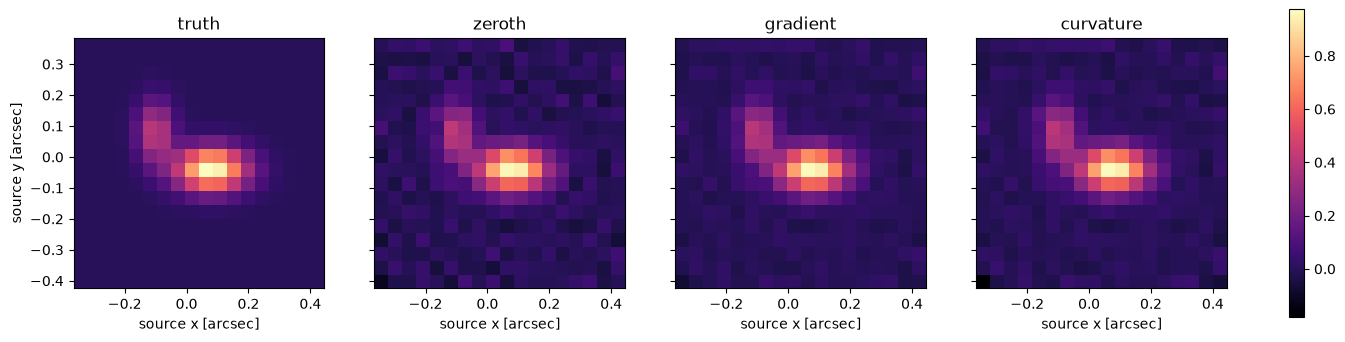

In [5]:
source_extent = (
    source_grid.centre[0] - source_grid.shape[1]*source_grid.pixel_scale/2,
    source_grid.centre[0] + source_grid.shape[1]*source_grid.pixel_scale/2,
    source_grid.centre[1] - source_grid.shape[0]*source_grid.pixel_scale/2,
    source_grid.centre[1] + source_grid.shape[0]*source_grid.pixel_scale/2,
)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
images = [('truth', true_source)] + [(k, np.asarray(v.source)) for k, v in results.items()]
limits = (min(np.min(v) for _, v in images), max(np.max(v) for _, v in images))
for axis, (title, values) in zip(axes, images):
    shown = axis.imshow(values, origin='lower', extent=source_extent, cmap='magma',
                        vmin=limits[0], vmax=limits[1])
    axis.set_title(title); axis.set_xlabel('source x [arcsec]')
axes[0].set_ylabel('source y [arcsec]')
fig.colorbar(shown, ax=axes, fraction=0.02); plt.show()

The linear solution is unconstrained, as in Warren & Dye, so noisy or poorly constrained source pixels may be negative. Positivity-constrained reconstruction would be a different optimization problem rather than the same closed-form semi-linear solve.

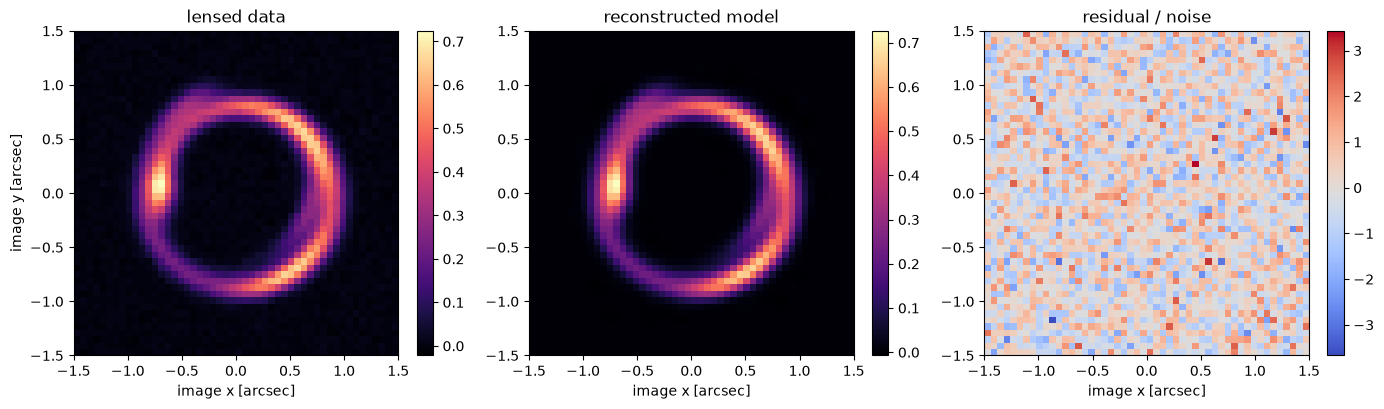

In [6]:
result = results['gradient']
image_extent = (-1.5, 1.5, -1.5, 1.5)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = (
    (observation.data, 'lensed data', 'magma'),
    (result.model_image, 'reconstructed model', 'magma'),
    (result.residuals, 'residual / noise', 'coolwarm'),
)
for axis, (values, title, cmap) in zip(axes, panels):
    shown = axis.imshow(values, origin='lower', extent=image_extent, cmap=cmap)
    axis.set_title(title); axis.set_xlabel('image x [arcsec]')
    fig.colorbar(shown, ax=axis, fraction=0.046)
axes[0].set_ylabel('image y [arcsec]')
fig.tight_layout(); plt.show()

This is intentionally a dense reference implementation: it makes every element of the forward operator inspectable and easy to validate. Large production datasets will require a sparse or matrix-free operator, but the scientific definitions and public reconstruction result can remain the same.